# 聚类

### 问题

前面所有模型都有标签 y,监督学习就是找 x 到 y 的映射。聚类是无监督的:手里只有一堆 x,目标是把相似的样本分到一组,组内的点尽量像,组间的尽量不像。

K-Means 是最直白的一种做法,轮流做两件事:

1. 固定中心,把每个点分给最近的中心;
2. 固定分配,把每个中心挪到它那组点的均值。

目标函数是组内平方和(inertia):

$$J=\sum_{i=1}^{n}\|x_i-\mu_{c_i}\|^2$$

每做一步 J 都会下降或者不变,所以一定会停,但停下来的地方可能是局部最优,跟初始中心关系很大。

它的假设也要记住:簇是球形的、大小差不多、每个特征的重要性一样。这几点后面都会用实验撞一遍。

## 1. 数据

造三簇点,500 个,标准差 0.8。先不看标签,直接当无标签数据来用。

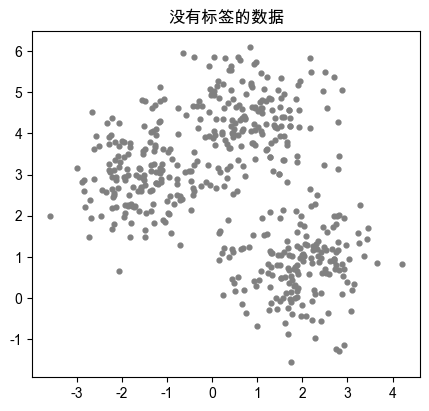

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

# 本机 numpy 2.0 会对 matmul 误报浮点警告,结果是对的
warnings.filterwarnings("ignore", message=".*in matmul")

# 中文和负号
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

from sklearn.datasets import make_blobs

X, y_true = make_blobs(n_samples=500, centers=3, cluster_std=0.8, random_state=0)

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(X[:, 0], X[:, 1], s=12, color="gray")
ax.set_title("没有标签的数据")
plt.show()

## 2. 手写一遍

随机挑三个点当初始中心,然后交替做分配和移动中心两步,每轮算一次 inertia。

In [2]:
rng = np.random.default_rng(0)
centers = X[rng.choice(len(X), 3, replace=False)]

for i in range(8):
    d = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    labels = d.argmin(axis=1)
    centers = np.array([X[labels == k].mean(axis=0) for k in range(3)])
    inertia = ((X - centers[labels]) ** 2).sum()
    print(f"第 {i + 1} 轮 inertia={inertia:.1f}")

第 1 轮 inertia=1720.7
第 2 轮 inertia=1412.5
第 3 轮 inertia=999.8
第 4 轮 inertia=654.0
第 5 轮 inertia=600.3
第 6 轮 inertia=595.0
第 7 轮 inertia=594.8
第 8 轮 inertia=594.8


inertia 从 1720 一路降到 594.8,第 7 轮之后中心不再动,算法就停了。整个过程没用到标签,也没用到梯度。

## 3. sklearn 版本

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)

print("inertia:", round(km.inertia_, 1))
print("聚类中心:", km.cluster_centers_.round(2))
print("和真实标签的一致度 ARI:", round(adjusted_rand_score(y_true, km.labels_), 4))

inertia: 594.8
聚类中心: [[-1.56  2.96]
 [ 1.93  0.78]
 [ 0.89  4.37]]
和真实标签的一致度 ARI: 0.9292


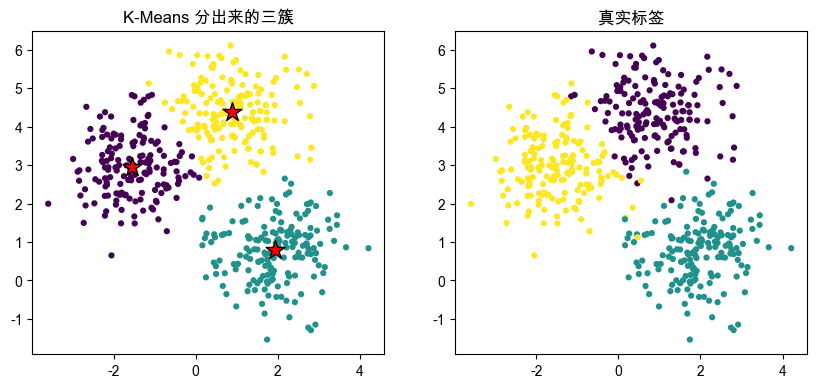

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))

axs[0].scatter(X[:, 0], X[:, 1], c=km.labels_, s=12, cmap="viridis")
axs[0].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
               c="red", marker="*", s=200, edgecolors="black")
axs[0].set_title("K-Means 分出来的三簇")

axs[1].scatter(X[:, 0], X[:, 1], c=y_true, s=12, cmap="viridis")
axs[1].set_title("真实标签")

plt.show()

ARI 0.929,分错的点都集中在两簇交界的地方,单看坐标确实分不清该归谁。

ARI 是 1 时表示和真实标签完全一致(类别编号怎么换都行),0 相当于随机分。这里 0.929 说明结构基本找对了。

## 4. k 要选几个

K-Means 不知道有几簇,得自己给。两个常用判断:inertia 的肘部,和轮廓系数。轮廓系数衡量的是点离自己簇有多近、离别的簇有多远,越接近 1 越好。

In [5]:
from sklearn.metrics import silhouette_score

ks = list(range(1, 9))
inertias, sils = [], []

for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inertias.append(m.inertia_)
    s = silhouette_score(X, m.labels_) if k > 1 else np.nan
    sils.append(s)
    print(f"k={k} inertia={m.inertia_:8.1f} silhouette={s:.3f}")

k=1 inertia=  2757.7 silhouette=nan
k=2 inertia=  1240.6 silhouette=0.513
k=3 inertia=   594.8 silhouette=0.554
k=4 inertia=   509.8 silhouette=0.460
k=5 inertia=   435.8 silhouette=0.359


k=6 inertia=   370.6 silhouette=0.344
k=7 inertia=   318.9 silhouette=0.344
k=8 inertia=   277.7 silhouette=0.351


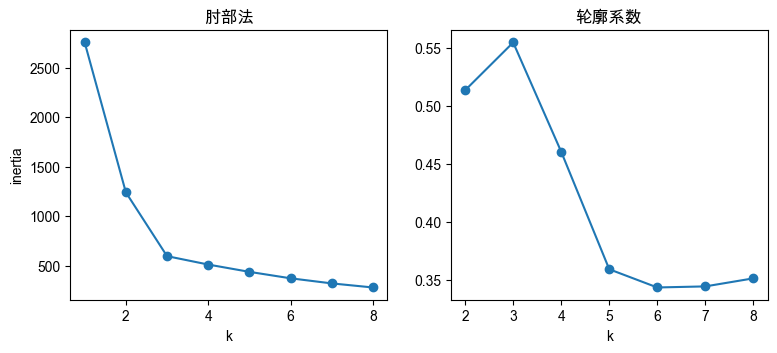

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))

axs[0].plot(ks, inertias, marker="o")
axs[0].set_xlabel("k")
axs[0].set_ylabel("inertia")
axs[0].set_title("肘部法")

axs[1].plot(ks[1:], sils[1:], marker="o")
axs[1].set_xlabel("k")
axs[1].set_title("轮廓系数")

plt.show()

inertia 从 k=1 的 2757.7 掉到 k=3 的 594.8,再往下每次只少几十,拐点很明显在 3。

轮廓系数在 k=3 是 0.554,k=4 掉到 0.460,后面越来越低。两种方法都指向 3。真实数据上这两个指标经常打架,那时候就要结合业务判断。

## 5. 初始化有多重要

K-Means 只保证收敛到局部最优。用 `init="random"` 换几个种子看看。

In [7]:
for seed in range(5):
    m = KMeans(n_clusters=3, init="random", n_init=1, random_state=seed).fit(X)
    print(f"seed={seed} inertia={m.inertia_:.1f}")

print("k-means++ :", round(KMeans(3, n_init=1, random_state=0).fit(X).inertia_, 1))

seed=0 inertia=1142.7
seed=1 inertia=594.8
seed=2 inertia=594.8
seed=3 inertia=594.8
seed=4 inertia=594.8
k-means++ : 594.8


五个种子里有一个卡在 1142.7,比最优的 594.8 差了快一倍,因为它把两簇合并了、另一簇劈成两半。

sklearn 默认 `init="k-means++"`,第一个中心随机,后面的中心倾向于选离已有中心远的点,所以从 k-means++ 出发基本都能到 594.8。再加上 `n_init=10` 跑十次取最好的,基本就稳了。

## 6. 非球形数据

K-Means 认为簇是球形的,遇到月牙形数据就会切错。

K-Means 每个簇的点数: [248 252] ARI: 0.245
DBSCAN 每个簇的点数: [250 250] ARI: 1.0


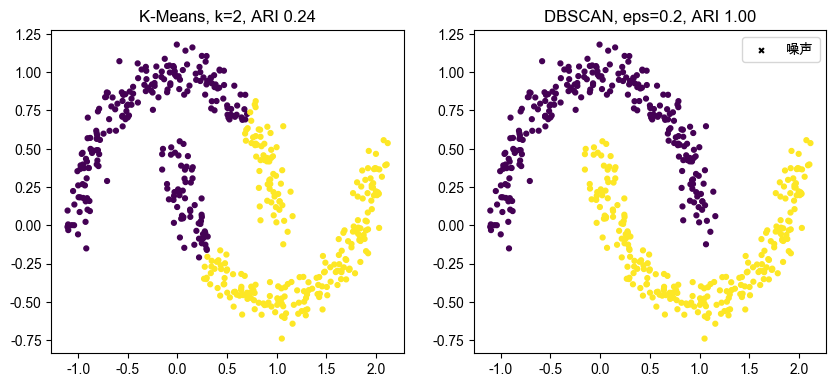

In [8]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X_m, y_m = make_moons(n_samples=500, noise=0.08, random_state=0)

km_m = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_m)
db = DBSCAN(eps=0.2, min_samples=5).fit(X_m)
noise = db.labels_ == -1

ari_km = adjusted_rand_score(y_m, km_m.labels_)
ari_db = adjusted_rand_score(y_m, db.labels_)
print("K-Means 每个簇的点数:", np.bincount(km_m.labels_), "ARI:", round(ari_km, 3))
print("DBSCAN 每个簇的点数:", np.bincount(db.labels_[~noise]), "ARI:", round(ari_db, 3))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))

axs[0].scatter(X_m[:, 0], X_m[:, 1], c=km_m.labels_, s=12, cmap="viridis")
axs[0].set_title(f"K-Means, k=2, ARI {ari_km:.2f}")

axs[1].scatter(X_m[~noise, 0], X_m[~noise, 1], c=db.labels_[~noise], s=12, cmap="viridis")
axs[1].scatter(X_m[noise, 0], X_m[noise, 1], c="black", s=12, marker="x", label="噪声")
axs[1].set_title(f"DBSCAN, eps=0.2, ARI {ari_db:.2f}")
axs[1].legend()

plt.show()

K-Means 只能在平面上切一条直线,两个半月一个在左上、一个在右下,它就把对角线当成了分界。结果每个簇都是 75% 的一个月牙加 25% 的另一个,ARI 只有 0.245。

这里有个陷阱:轮廓系数还有 0.486,看着不差。它只管簇内紧不紧、簇间远不远,不管形状,所以这种切一刀各拿一半的分法也能拿高分。判断聚类效果时,指标之外还得看一眼图。

DBSCAN 不是找中心,而是从每个点出发,把 eps 范围内密度够的点连成一片,所以能顺着月牙的弯走,还能把离群点标成噪声。

eps 得试:

In [9]:
for eps in [0.1, 0.15, 0.2, 0.3]:
    m = DBSCAN(eps=eps, min_samples=5).fit(X_m)
    n_cluster = len(set(m.labels_)) - (1 if -1 in m.labels_ else 0)
    print(f"eps={eps:<5} 簇数={n_cluster} 噪声点={(m.labels_ == -1).sum()}")

eps=0.1   簇数=5 噪声点=22
eps=0.15  簇数=2 噪声点=1
eps=0.2   簇数=2 噪声点=0
eps=0.3   簇数=1 噪声点=0


eps=0.1 太紧,月牙被切成了 5 段,还有 22 个点被判成噪声;0.2 正好两个簇;0.3 太松,两簇连成了一片。

DBSCAN 不用指定簇数,但要给 eps 和 min_samples,而且对数据密度很敏感。实际用的时候一般先画 k-距离曲线来挑 eps。

## 7. 小结

- K-Means 是交替优化,每一步 inertia 都下降,但只保证局部最优;
- 初始化很重要,用默认的 k-means++ 加上 n_init 多跑几次;
- k 要自己选,肘部法和轮廓系数是两把常用的尺子;
- 它对球形、等大小、等权重的簇有隐含假设,月牙形数据直接失效;
- 特征要先标准化,不然量纲大的特征会把距离垄断,和 KNN、SVM 一样;
- DBSCAN 不假设形状,能找出噪声,但换成密度不均匀的数据又会有新问题。